# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

### Approach

1. Load the cleaned dataset produced by `Aviation_Accidents_Cleaning.ipynb` (professional-build airplanes, events from 1983 onwards).
2. Split plane types into **small** and **large** (more than 20 people aboard) and compare them.
3. Rank **makes** and then specific **plane types** on the two client metrics:
   - `Fatal.Serious.Fraction`, the share of people aboard who were fatally or seriously injured,
   - `Destroyed`, the share of accidents in which the aircraft was destroyed.
4. Make every comparison statistically defensible: minimum sample sizes, 95% confidence intervals on every rate, and significance tests (Welch t-test, chi-square, Kruskal-Wallis) when claiming that one group differs from another.
5. Examine **weather**, **engine type and count**, **phase of flight** and **purpose of flight** as factors behind injury and damage.

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
os.makedirs('images', exist_ok=True)

def save(fig, name):
    """Save a figure to the images folder for the README/presentation."""
    fig.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')

# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
os.makedirs('images', exist_ok=True)

def save(fig, name):
    """Save a figure to the images folder for the README/presentation."""
    fig.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')

In [2]:
df = pd.read_csv('data/AviationData_cleaned.csv', parse_dates=['Event.Date'])
print(f"{len(df):,} events | {df['Make'].nunique()} makes | {df['Make.Model'].nunique():,} plane types")
df.head()

60,240 events | 56 makes | 4,382 plane types


,Event.Id,Investigation.Type,Event.Date,Location,Country,Injury.Severity,Aircraft.damage,Make,Model,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Year,Total.Passengers,Fatal.Serious.Injuries,Fatal.Serious.Fraction,Destroyed,Make.Model
0,20001214X42095,Accident,1983-01-01,"NEWPORT, OR",United States,Non-Fatal,Substantial,Cessna,182P,1.0,Reciprocating,Personal,0.0,0.0,1.0,3.0,VMC,Approach,1983,4.0,0.0,0.0,0,Cessna 182P
1,20001214X42067,Accident,1983-01-01,"WOODBINE, IA",United States,Non-Fatal,Substantial,Cessna,182RG,1.0,Reciprocating,Personal,0.0,0.0,0.0,2.0,VMC,Landing,1983,2.0,0.0,0.0,0,Cessna 182RG
2,20001214X42063,Accident,1983-01-01,"MARYVILLE, MO",United States,Non-Fatal,Substantial,Cessna,182P,1.0,Reciprocating,Personal,0.0,0.0,0.0,1.0,VMC,Takeoff,1983,1.0,0.0,0.0,0,Cessna 182P
3,20001214X42018,Accident,1983-01-01,"UPLAND, CA",United States,Non-Fatal,Substantial,Piper,PA-28R-200,1.0,Reciprocating,Personal,0.0,0.0,2.0,0.0,VMC,Approach,1983,2.0,0.0,0.0,0,Piper PA-28R-200
4,20001214X41951,Accident,1983-01-01,"SPRINGBROOK, WI",United States,Non-Fatal,Substantial,Cessna,140,1.0,Reciprocating,Instructional,0.0,0.0,0.0,2.0,VMC,Landing,1983,2.0,0.0,0.0,0,Cessna 140


**Helper functions** used throughout the notebook:
- `wilson_ci`: 95% Wilson score interval for a proportion such as the destruction rate. It stays accurate for small samples and for rates near 0, where the usual normal approximation breaks down.
- `safety_summary`: for any grouping, returns the number of events, the mean fatal/serious fraction with a 95% confidence interval (mean ± 1.96 × standard error), and the destruction rate with its Wilson interval. A minimum sample size can be applied.

In [3]:
Z = 1.96  # 95% confidence

def wilson_ci(successes, n, z=Z):
    """95% Wilson score interval for a proportion (well behaved for rates near 0)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

def fmt_p(p):
    """Readable p-value (values below 1e-300 underflow to 0 in floating point)."""
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}'

def safety_summary(data, by, min_n=1):
    """Per-group sample size, mean fatal/serious fraction (with 95% CI) and destruction rate (with Wilson 95% CI)."""
    g = data.groupby(by)
    out = pd.DataFrame({
        'n_events': g.size(),
        'mean_fatal_serious_frac': g['Fatal.Serious.Fraction'].mean(),
        'sem_fatal_serious_frac': g['Fatal.Serious.Fraction'].sem(),
        'destroyed_rate': g['Destroyed'].mean(),
        'destroyed_count': g['Destroyed'].sum(),
    })
    out['fs_ci_low'] = (out['mean_fatal_serious_frac'] - Z * out['sem_fatal_serious_frac']).clip(lower=0)
    out['fs_ci_high'] = out['mean_fatal_serious_frac'] + Z * out['sem_fatal_serious_frac']
    lo, hi = wilson_ci(out['destroyed_count'], out['n_events'])
    out['destroyed_ci_low'], out['destroyed_ci_high'] = lo, hi
    return out[out['n_events'] >= min_n]

### Plane-type identifier for airliners

The cleaning notebook created `Make.Model` as a unique plane-type key. For airliners that key is badly fragmented: customer codes (`737-7H4`, `737-8K5`), spacing (`7377H4`) and inconsistent manufacturer names split one aircraft type into dozens of labels with one or two events each. That makes it impossible to reach the required minimum of ten events per type. The next cell groups airliner labels into **model families** with a single canonical name (for example, every Boeing 737 variant becomes `Boeing 737`, and CRJs filed under Bombardier or Canadair become `Bombardier CRJ (CL-600)`). All other aircraft keep their exact `Make.Model`.

In [4]:
# Model labels for airliners are fragmented by customer codes, spacing and even make spelling
# (e.g. "737-7H4", "7377H4", "B737-300"; DC-9s filed under both Douglas and McDonnell Douglas;
# CRJs under Bombardier and Canadair). To get enough events per plane type, airliner models are
# grouped into model families with one canonical name. Every other plane keeps its exact Make + Model.
import re

def model_family(make, model):
    m = re.sub(r'[^A-Z0-9]', '', str(model).upper())
    m = re.sub(r'^(BOEING|B)(?=7\d7)', '', m)                          # B737 / BOEING737 -> 737
    if make in ('Boeing', 'Mcdonnell Douglas', 'Douglas'):
        if re.match(r'^(MD8\d|DC98\d)', m):  return 'McDonnell Douglas MD-80 series'
        if m.startswith('MD9'):               return 'McDonnell Douglas MD-90'
        if m.startswith('MD11'):              return 'McDonnell Douglas MD-11'
        if m.startswith('DC10'):              return 'McDonnell Douglas DC-10'
        if m.startswith('DC9'):               return 'McDonnell Douglas DC-9'
        if m.startswith('DC8'):               return 'McDonnell Douglas DC-8'
        hit = re.match(r'^(7[0-9]7)', m)
        if hit and make == 'Boeing':          return f'Boeing {hit.group(1)}'
    if make == 'Airbus':
        hit = re.match(r'^A?(3[0-9]{2})', m)
        if hit:
            fam = hit.group(1)
            return 'Airbus A320 family' if fam in ('318', '319', '320', '321') else f'Airbus A{fam}'
    if make in ('Bombardier', 'Canadair') and ('CL600' in m or 'CRJ' in m or 'RJ' in m):
        return 'Bombardier CRJ (CL-600)'
    if make in ('Bombardier', 'De Havilland', 'Boeing') and re.search(r'DHC8|DH8|DASH8', m):
        return 'De Havilland/Bombardier Dash 8'
    if make == 'Embraer':
        if re.match(r'^(EMB|ERJ|E)?1[34]5', m):         return 'Embraer ERJ-135/145'
        if re.match(r'^(EMB|ERJ)?1[79]0', m):          return 'Embraer E-Jet (E170/E190)'
        if re.match(r'^(EMB)?120', m):                  return 'Embraer EMB-120 Brasilia'
    if make == 'Lockheed' and 'L1011' in m:            return 'Lockheed L-1011'
    if make == 'British Aerospace' and re.search(r'146|RJ[0-9]{2}', m): return 'BAe 146 / Avro RJ'
    return f'{make} {model}'

df['Model.Family'] = [model_family(a, b) for a, b in zip(df['Make'], df['Model'])]
print(f"Plane types: {df['Make.Model'].nunique():,} raw Make.Model labels -> {df['Model.Family'].nunique():,} after grouping airliner families")
df[df['Model.Family'] != df['Make.Model']]['Model.Family'].value_counts().head(20)

Plane types: 4,382 raw Make.Model labels -> 3,825 after grouping airliner families


Model.Family
Boeing 737                        230
Boeing 727                        170
Boeing 747                        123
Bombardier CRJ (CL-600)           114
McDonnell Douglas MD-80 series    113
McDonnell Douglas DC-9            100
Airbus A320 family                 79
De Havilland/Bombardier Dash 8     69
McDonnell Douglas DC-10            66
Boeing 757                         62
McDonnell Douglas DC-8             53
Boeing 767                         53
McDonnell Douglas MD-11            49
Embraer ERJ-135/145                45
Airbus A300                        25
Boeing 777                         24
Embraer EMB-120 Brasilia           23
Boeing 707                         21
Embraer E-Jet (E170/E190)          20
Lockheed L-1011                    17
Name: count, dtype: int64

df = pd.read_csv('data/AviationData_cleaned.csv', parse_dates=['Event.Date'])
print(f"{len(df):,} events | {df['Make'].nunique()} makes | {df['Make.Model'].nunique():,} plane types")
df.head()

**How size is assigned.** The dataset has no seat-count column, and a single event is a noisy guide to aircraft size. A Boeing 747 freighter may be flying with 3 crew, and a light airplane involved in a collision can have the other aircraft's occupants recorded. Size is therefore assigned per **plane type**: a type is **Large** if the 90th percentile of people aboard across its events is above **20** *and* it is multi-engine. Every row of that type inherits the label.

In [5]:
PASSENGER_THRESHOLD = 20

# Typical occupancy of each plane type: the 90th percentile of people on board across its events.
# A single event is a noisy guide to aircraft size: an airliner may fly a ferry/cargo leg with 3 crew,
# and a small plane involved in a collision can have the other aircraft's occupants recorded.
# Many airliner events are cargo, ferry or positioning flights with only a few crew aboard, so a high
# percentile of the type's recorded occupancy is used as a proxy for its passenger capacity.
type_stats = df.groupby('Model.Family').agg(
    occupancy_q90=('Total.Passengers', lambda s: s.quantile(0.90)),
    typical_engines=('Number.of.Engines', 'median'),
)
# Large = typical occupancy above 20 AND multi-engine (no single-engine plane in this data carries 20+)
type_stats['Plane.Size'] = np.where(
    (type_stats['occupancy_q90'] > PASSENGER_THRESHOLD) & (type_stats['typical_engines'] >= 2),
    'Large', 'Small')
df['Plane.Size'] = df['Model.Family'].map(type_stats['Plane.Size'])

small = df[df['Plane.Size'] == 'Small'].copy()
large = df[df['Plane.Size'] == 'Large'].copy()
print(df['Plane.Size'].value_counts())
print()
print("Largest plane types in each group by number of events:")
print("Small:", small['Model.Family'].value_counts().head(8).index.tolist())
print("Large:", large['Model.Family'].value_counts().head(8).index.tolist())

Plane.Size
Small    58373
Large     1867
Name: count, dtype: int64

Largest plane types in each group by number of events:
Small: ['Cessna 152', 'Cessna 172', 'Cessna 172N', 'Piper PA-28-140', 'Cessna 172M', 'Cessna 150', 'Cessna 172P', 'Cessna 182']
Large: ['Boeing 737', 'Boeing 727', 'Boeing 747', 'Bombardier CRJ (CL-600)', 'McDonnell Douglas MD-80 series', 'McDonnell Douglas DC-9', 'Airbus A320 family', 'Boeing 757']


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Plane.Size,,,,,,,
Large,1867,0.121,0.107,0.135,0.136,0.121,0.152
Small,58373,0.276,0.272,0.279,0.213,0.210,0.217


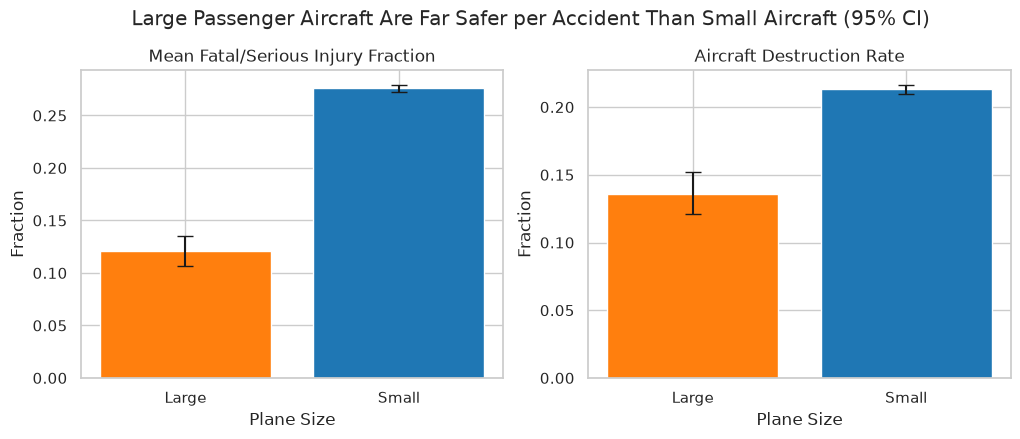

In [6]:
overview = safety_summary(df, 'Plane.Size')
display(overview[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                  'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, lo, hi, title in [
    (axes[0], 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high', 'Mean Fatal/Serious Injury Fraction'),
    (axes[1], 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high', 'Aircraft Destruction Rate')]:
    err = [overview[col] - overview[lo], overview[hi] - overview[col]]
    ax.bar(overview.index, overview[col], yerr=err, capsize=6, color=['tab:orange', 'tab:blue'])
    ax.set_title(title)
    ax.set_ylabel('Fraction')
    ax.set_xlabel('Plane Size')
fig.suptitle('Large Passenger Aircraft Are Far Safer per Accident Than Small Aircraft (95% CI)', y=1.03)
save(fig, 'size_overview')
plt.show()

**Small vs. large:** accidents in large passenger aircraft are much less severe. On average about **12%** of occupants are fatally or seriously injured, against about **28%** in small aircraft, and the aircraft is destroyed in about **14%** of accidents against **21%**. The confidence intervals don't overlap, so this difference is clearly not due to chance. The two groups have very different risk profiles, which is why they get separate recommendations below.

Z = 1.96  # 95% confidence

def wilson_ci(successes, n, z=Z):
    """95% Wilson score interval for a proportion (well behaved for rates near 0)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

def fmt_p(p):
    """Readable p-value (values below 1e-300 underflow to 0 in floating point)."""
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}'

def safety_summary(data, by, min_n=1):
    """Per-group sample size, mean fatal/serious fraction (with 95% CI) and destruction rate (with Wilson 95% CI)."""
    g = data.groupby(by)
    out = pd.DataFrame({
        'n_events': g.size(),
        'mean_fatal_serious_frac': g['Fatal.Serious.Fraction'].mean(),
        'sem_fatal_serious_frac': g['Fatal.Serious.Fraction'].sem(),
        'destroyed_rate': g['Destroyed'].mean(),
        'destroyed_count': g['Destroyed'].sum(),
    })
    out['fs_ci_low'] = (out['mean_fatal_serious_frac'] - Z * out['sem_fatal_serious_frac']).clip(lower=0)
    out['fs_ci_high'] = out['mean_fatal_serious_frac'] + Z * out['sem_fatal_serious_frac']
    lo, hi = wilson_ci(out['destroyed_count'], out['n_events'])
    out['destroyed_ci_low'], out['destroyed_ci_high'] = lo, hi
    return out[out['n_events'] >= min_n]

To keep the averages statistically meaningful, small-aircraft makes need at least **50** events (the threshold used in cleaning). Large aircraft have far fewer events overall, so large-aircraft makes need at least **20**. Only 10 large-aircraft makes meet that bar, so the large-aircraft charts show all 10 rather than 15. Error bars are 95% confidence intervals, and `n` is the number of events behind each average.

In [7]:
# Minimum sample sizes so averages are statistically meaningful
MIN_SMALL_MAKE = 50   # small-aircraft makes already have >=50 events overall (cleaning threshold)
MIN_LARGE_MAKE = 20   # far fewer large-aircraft events exist, so 20 is used for large makes

small_makes = safety_summary(small, 'Make', MIN_SMALL_MAKE).sort_values('mean_fatal_serious_frac')
large_makes = safety_summary(large, 'Make', MIN_LARGE_MAKE).sort_values('mean_fatal_serious_frac')
print(f"Small makes with >= {MIN_SMALL_MAKE} events: {len(small_makes)}")
print(f"Large makes with >= {MIN_LARGE_MAKE} events: {len(large_makes)}")

small_top15 = small_makes.head(15)
large_top15 = large_makes.head(15)
cols = ['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high', 'destroyed_rate']
print("\nSmall aircraft: 15 makes with the lowest mean fatal/serious fraction")
display(small_top15[cols].round(3))
print("Large aircraft: makes with the lowest mean fatal/serious fraction")
display(large_top15[cols].round(3))

Small makes with >= 50 events: 50
Large makes with >= 20 events: 10

Small aircraft: 15 makes with the lowest mean fatal/serious fraction


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate
Make,,,,,
Waco,138,0.103,0.055,0.150,0.087
Cub Crafters,69,0.138,0.060,0.216,0.000
Helio,105,0.141,0.077,0.205,0.124
Maule,570,0.155,0.126,0.183,0.093
Great Lakes,59,0.161,0.068,0.254,0.136
Schweizer,140,0.171,0.109,0.234,0.200
Boeing Stearman,389,0.175,0.139,0.211,0.103
Stinson,432,0.199,0.164,0.235,0.130
Swearingen,155,0.205,0.144,0.266,0.200


Large aircraft: makes with the lowest mean fatal/serious fraction


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate
Make,,,,,
Mcdonnell Douglas,294,0.069,0.042,0.095,0.105
Lockheed,31,0.079,0.000,0.167,0.129
Bombardier,84,0.092,0.034,0.149,0.083
Boeing,945,0.105,0.086,0.124,0.119
Embraer,90,0.126,0.063,0.189,0.100
Airbus,137,0.153,0.095,0.212,0.168
Canadair,41,0.196,0.080,0.312,0.195
De Havilland,82,0.218,0.135,0.302,0.220
Douglas,107,0.223,0.146,0.299,0.243


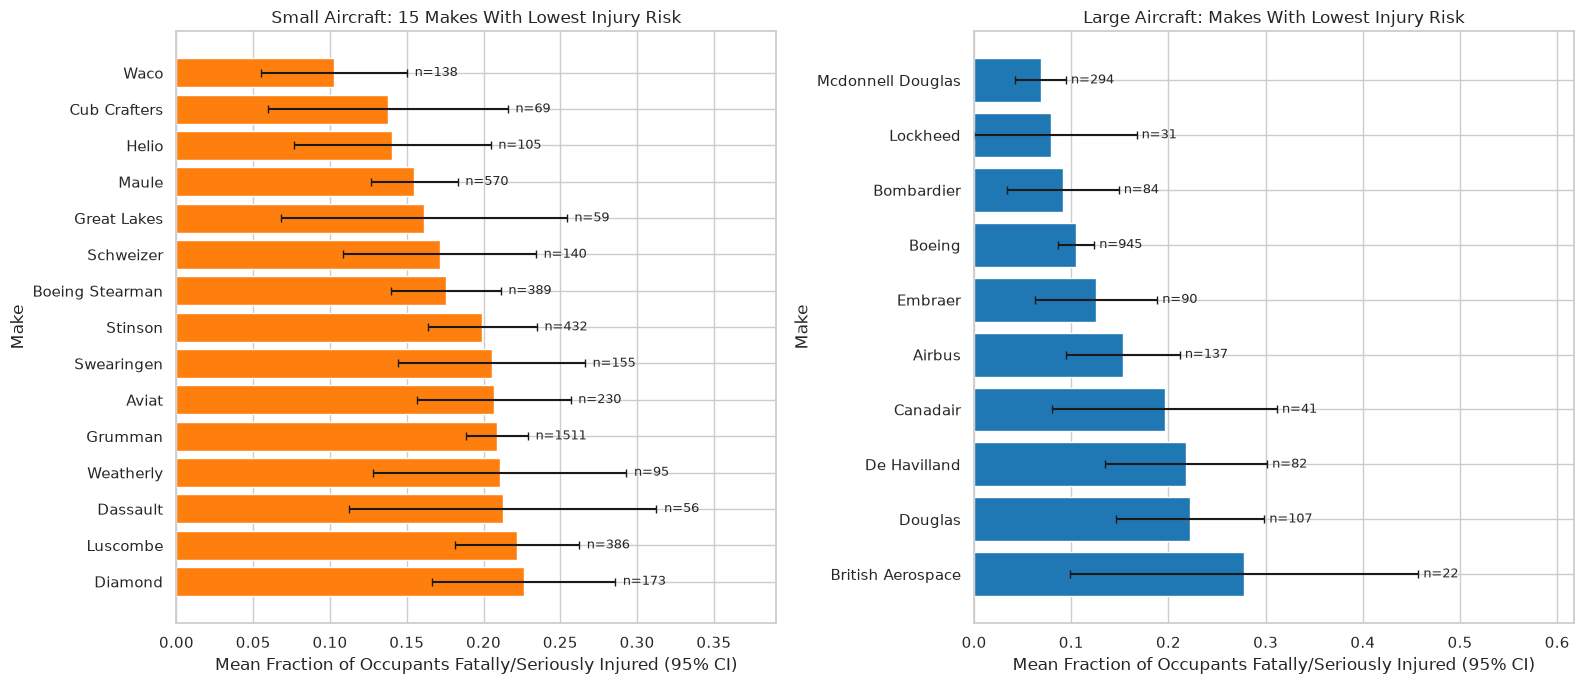

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title, color in [
        (axes[0], small_top15, 'Small Aircraft: 15 Makes With Lowest Injury Risk', 'tab:orange'),
        (axes[1], large_top15, 'Large Aircraft: Makes With Lowest Injury Risk', 'tab:blue')]:
    err = [data['mean_fatal_serious_frac'] - data['fs_ci_low'],
           data['fs_ci_high'] - data['mean_fatal_serious_frac']]
    ax.barh(data.index[::-1], data['mean_fatal_serious_frac'][::-1],
            xerr=[e[::-1] for e in err], capsize=3, color=color)
    for i, (make, row) in enumerate(data[::-1].iterrows()):
        ax.text(row['fs_ci_high'] + 0.005, i, f"n={int(row['n_events'])}", va='center', fontsize=9)
    ax.set_title(title)
    ax.set_xlabel('Mean Fraction of Occupants Fatally/Seriously Injured (95% CI)')
    ax.set_ylabel('Make')
axes[0].set_xlim(0, small_top15['fs_ci_high'].max() * 1.25)
axes[1].set_xlim(0, large_top15['fs_ci_high'].max() * 1.35)
fig.tight_layout()
save(fig, 'makes_injury_fraction')
plt.show()

# Model labels for airliners are fragmented by customer codes, spacing and even make spelling
# (e.g. "737-7H4", "7377H4", "B737-300"; DC-9s filed under both Douglas and McDonnell Douglas;
# CRJs under Bombardier and Canadair). To get enough events per plane type, airliner models are
# grouped into model families with one canonical name. Every other plane keeps its exact Make + Model.
import re

def model_family(make, model):
    m = re.sub(r'[^A-Z0-9]', '', str(model).upper())
    m = re.sub(r'^(BOEING|B)(?=7\d7)', '', m)                          # B737 / BOEING737 -> 737
    if make in ('Boeing', 'Mcdonnell Douglas', 'Douglas'):
        if re.match(r'^(MD8\d|DC98\d)', m):  return 'McDonnell Douglas MD-80 series'
        if m.startswith('MD9'):               return 'McDonnell Douglas MD-90'
        if m.startswith('MD11'):              return 'McDonnell Douglas MD-11'
        if m.startswith('DC10'):              return 'McDonnell Douglas DC-10'
        if m.startswith('DC9'):               return 'McDonnell Douglas DC-9'
        if m.startswith('DC8'):               return 'McDonnell Douglas DC-8'
        hit = re.match(r'^(7[0-9]7)', m)
        if hit and make == 'Boeing':          return f'Boeing {hit.group(1)}'
    if make == 'Airbus':
        hit = re.match(r'^A?(3[0-9]{2})', m)
        if hit:
            fam = hit.group(1)
            return 'Airbus A320 family' if fam in ('318', '319', '320', '321') else f'Airbus A{fam}'
    if make in ('Bombardier', 'Canadair') and ('CL600' in m or 'CRJ' in m or 'RJ' in m):
        return 'Bombardier CRJ (CL-600)'
    if make in ('Bombardier', 'De Havilland', 'Boeing') and re.search(r'DHC8|DH8|DASH8', m):
        return 'De Havilland/Bombardier Dash 8'
    if make == 'Embraer':
        if re.match(r'^(EMB|ERJ|E)?1[34]5', m):         return 'Embraer ERJ-135/145'
        if re.match(r'^(EMB|ERJ)?1[79]0', m):          return 'Embraer E-Jet (E170/E190)'
        if re.match(r'^(EMB)?120', m):                  return 'Embraer EMB-120 Brasilia'
    if make == 'Lockheed' and 'L1011' in m:            return 'Lockheed L-1011'
    if make == 'British Aerospace' and re.search(r'146|RJ[0-9]{2}', m): return 'BAe 146 / Avro RJ'
    return f'{make} {model}'

df['Model.Family'] = [model_family(a, b) for a, b in zip(df['Make'], df['Model'])]
print(f"Plane types: {df['Make.Model'].nunique():,} raw Make.Model labels -> {df['Model.Family'].nunique():,} after grouping airliner families")
df[df['Model.Family'] != df['Make.Model']]['Model.Family'].value_counts().head(20)

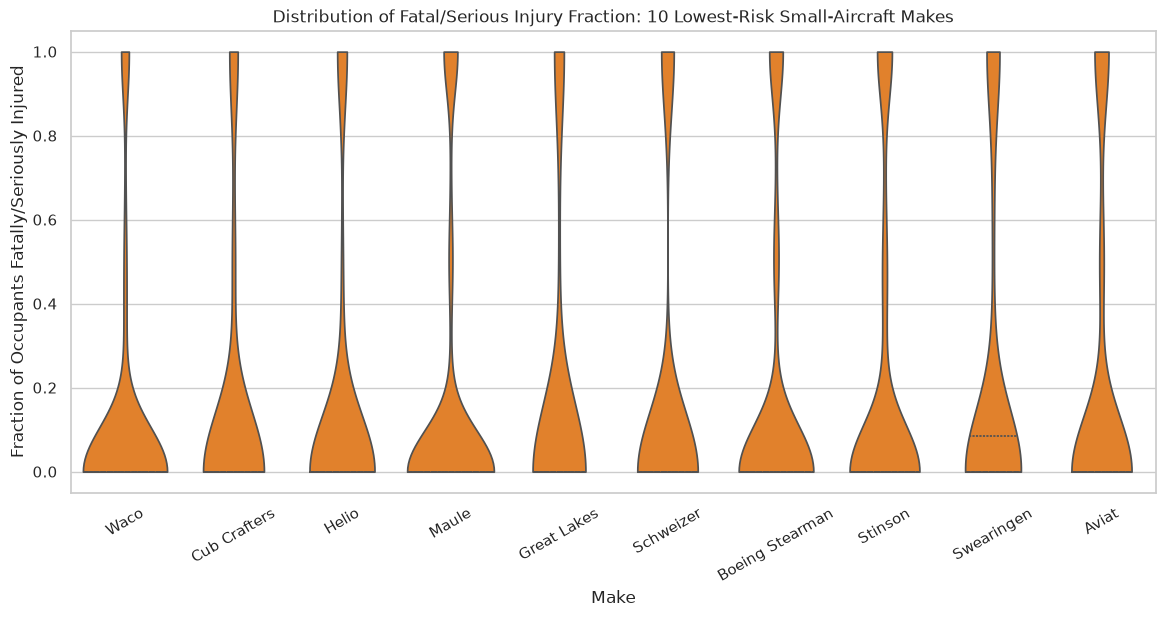

,share_no_serious_injury,share_all_aboard_hurt,median
Make,,,
Waco,0.870,0.080,0.0
Cub Crafters,0.841,0.116,0.0
Helio,0.829,0.124,0.0
Maule,0.819,0.130,0.0
Great Lakes,0.831,0.153,0.0
Schweizer,0.829,0.171,0.0
Boeing Stearman,0.794,0.144,0.0
Stinson,0.757,0.160,0.0
Swearingen,0.735,0.174,0.0


In [9]:
small_top10_makes = small_makes.head(10).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(small_top10_makes)], x='Make', y='Fatal.Serious.Fraction',
               order=small_top10_makes, cut=0, inner='quartile', color='tab:orange', ax=ax)
ax.set_title('Distribution of Fatal/Serious Injury Fraction: 10 Lowest-Risk Small-Aircraft Makes')
ax.set_xlabel('Make')
ax.set_ylabel('Fraction of Occupants Fatally/Seriously Injured')
ax.tick_params(axis='x', rotation=30)
save(fig, 'small_makes_violin')
plt.show()

# How concentrated are the outcomes? Share of events with no fatal/serious injuries at all
(small[small['Make'].isin(small_top10_makes)]
     .groupby('Make')['Fatal.Serious.Fraction']
     .agg(share_no_serious_injury=lambda s: (s == 0).mean(),
          share_all_aboard_hurt=lambda s: (s == 1).mean(),
          median='median')
     .loc[small_top10_makes].round(3))

**Reading the violin plot:** the injury fraction is strongly **bimodal**. Most accidents injure nobody seriously (fraction = 0), a smaller group are catastrophic (fraction = 1, everyone aboard hurt), and few are in between. For every one of these makes the median is 0. The mean is driven by how often the catastrophic outcome occurs, which is why the mean (with its confidence interval) and the share of events with any serious injury are the right summaries, rather than the median.

**How size is assigned.** The dataset has no seat-count column, and a single event is a noisy guide to aircraft size. A Boeing 747 freighter may be flying with 3 crew, and a light airplane involved in a collision can have the other aircraft's occupants recorded. Size is therefore assigned per **plane type**: a type is **Large** if the 90th percentile of people aboard across its events is above **20** *and* it is multi-engine. Every row of that type inherits the label.

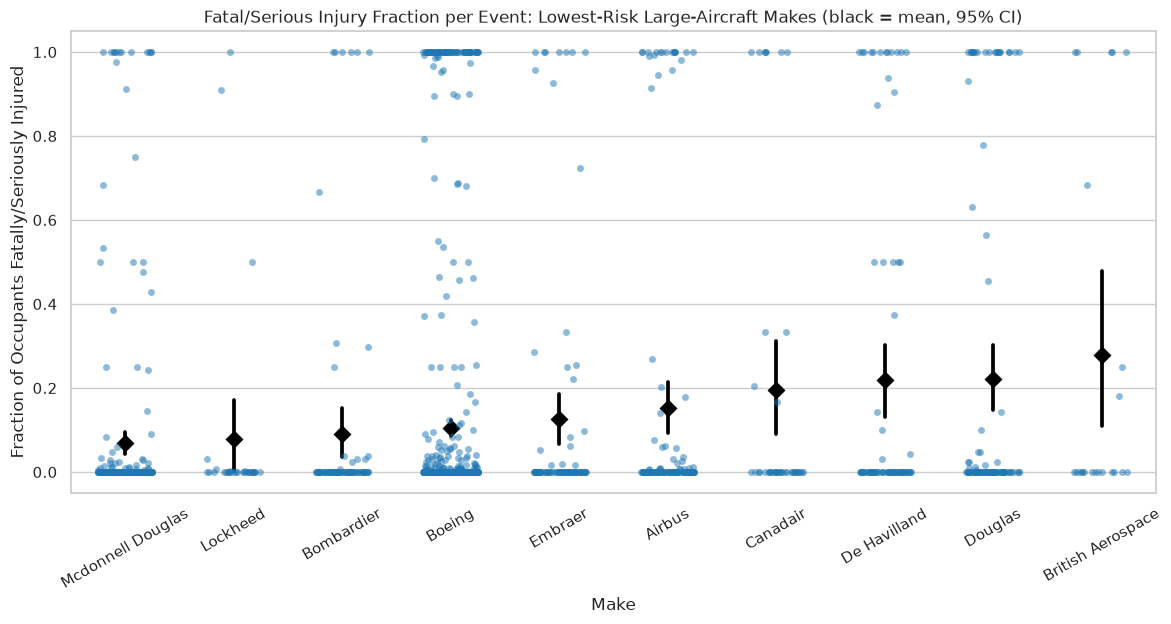

In [10]:
large_top10_makes = large_makes.head(10).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.stripplot(data=large[large['Make'].isin(large_top10_makes)], x='Make', y='Fatal.Serious.Fraction',
              order=large_top10_makes, jitter=0.25, alpha=0.5, color='tab:blue', ax=ax)
sns.pointplot(data=large[large['Make'].isin(large_top10_makes)], x='Make', y='Fatal.Serious.Fraction',
              order=large_top10_makes, color='black', linestyle='none', markers='D', errorbar=('ci', 95), ax=ax)
ax.set_title('Fatal/Serious Injury Fraction per Event: Lowest-Risk Large-Aircraft Makes (black = mean, 95% CI)')
ax.set_xlabel('Make')
ax.set_ylabel('Fraction of Occupants Fatally/Seriously Injured')
ax.tick_params(axis='x', rotation=30)
save(fig, 'large_makes_strip')
plt.show()

**Reading the strip plot:** large-aircraft accidents are overwhelmingly at or near 0. A typical airliner event is turbulence or a ground incident in which one or two of 150 people are seriously hurt. The mean is pulled up by a small number of cargo/ferry flights (few people aboard) and rare hull-loss crashes. McDonnell Douglas, Bombardier and Boeing combine low means with tight intervals. Lockheed's interval is very wide (only 31 events), so its low mean is not reliable.

overview = safety_summary(df, 'Plane.Size')
display(overview[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                  'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, lo, hi, title in [
    (axes[0], 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high', 'Mean Fatal/Serious Injury Fraction'),
    (axes[1], 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high', 'Aircraft Destruction Rate')]:
    err = [overview[col] - overview[lo], overview[hi] - overview[col]]
    ax.bar(overview.index, overview[col], yerr=err, capsize=6, color=['tab:orange', 'tab:blue'])
    ax.set_title(title)
    ax.set_ylabel('Fraction')
    ax.set_xlabel('Plane Size')
fig.suptitle('Large Passenger Aircraft Are Far Safer per Accident Than Small Aircraft (95% CI)', y=1.03)
save(fig, 'size_overview')
plt.show()

Small aircraft: 15 makes with the lowest destruction rate


,n_events,destroyed_count,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Make,,,,,
Cub Crafters,69,0,0.000,0.000,0.053
Aviat,230,16,0.070,0.043,0.110
Diamond,173,13,0.075,0.044,0.124
Flight Design,79,6,0.076,0.035,0.156
Waco,138,12,0.087,0.050,0.146
Maule,570,53,0.093,0.072,0.120
Boeing Stearman,389,40,0.103,0.076,0.137
Luscombe,386,40,0.104,0.077,0.138
Taylorcraft,375,45,0.120,0.091,0.157


Large aircraft: makes with the lowest destruction rate


,n_events,destroyed_count,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Make,,,,,
Bombardier,84,7,0.083,0.041,0.162
Embraer,90,9,0.100,0.054,0.179
Mcdonnell Douglas,294,31,0.105,0.075,0.146
Boeing,945,112,0.119,0.099,0.141
Lockheed,31,4,0.129,0.051,0.289
Airbus,137,23,0.168,0.115,0.239
Canadair,41,8,0.195,0.102,0.340
De Havilland,82,18,0.220,0.144,0.321
Douglas,107,26,0.243,0.172,0.332


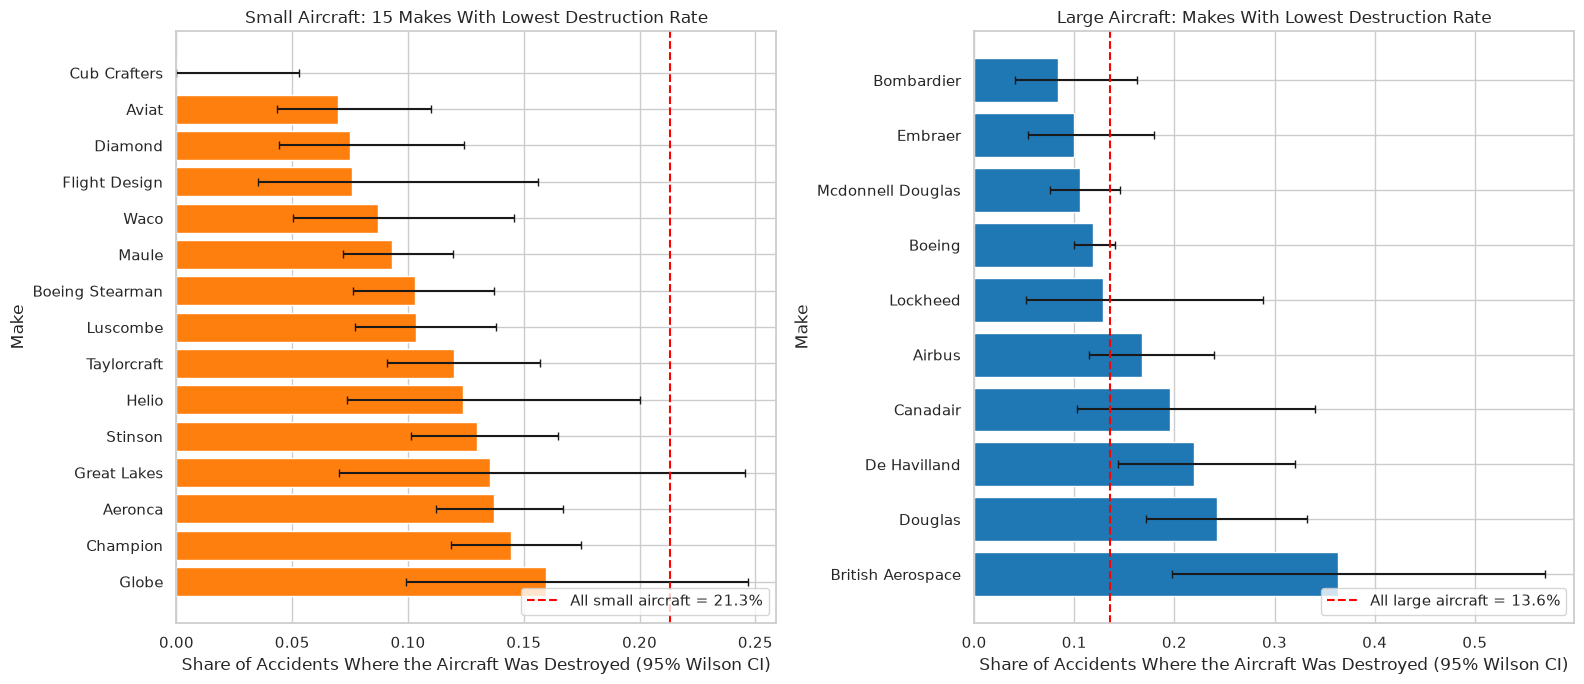

In [11]:
small_destroyed = safety_summary(small, 'Make', MIN_SMALL_MAKE).sort_values('destroyed_rate').head(15)
large_destroyed = safety_summary(large, 'Make', MIN_LARGE_MAKE).sort_values('destroyed_rate').head(15)
cols = ['n_events', 'destroyed_count', 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']
print("Small aircraft: 15 makes with the lowest destruction rate")
display(small_destroyed[cols].round(3))
print("Large aircraft: makes with the lowest destruction rate")
display(large_destroyed[cols].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title, color, overall in [
        (axes[0], small_destroyed, 'Small Aircraft: 15 Makes With Lowest Destruction Rate', 'tab:orange', small['Destroyed'].mean()),
        (axes[1], large_destroyed, 'Large Aircraft: Makes With Lowest Destruction Rate', 'tab:blue', large['Destroyed'].mean())]:
    err = [data['destroyed_rate'] - data['destroyed_ci_low'], data['destroyed_ci_high'] - data['destroyed_rate']]
    ax.barh(data.index[::-1], data['destroyed_rate'][::-1], xerr=[e[::-1] for e in err], capsize=3, color=color)
    ax.axvline(overall, color='red', linestyle='--', label=f'All {title.split(":")[0].lower()} = {overall:.1%}')
    ax.set_title(title)
    ax.set_xlabel('Share of Accidents Where the Aircraft Was Destroyed (95% Wilson CI)')
    ax.set_ylabel('Make')
    ax.legend(loc='lower right')
fig.tight_layout()
save(fig, 'makes_destroyed_rate')
plt.show()

**Combining both metrics.** The client cares about injuries *and* hull losses, so each make is ranked on both and the two ranks are averaged. A significance test then checks whether the best small-aircraft makes really differ from the rest of the small fleet.

In [12]:
# Combined make scorecard: rank on both metrics, then average the ranks (lower = safer)
def scorecard(summary):
    s = summary.copy()
    s['injury_rank'] = s['mean_fatal_serious_frac'].rank()
    s['destroyed_rank'] = s['destroyed_rate'].rank()
    s['combined_rank'] = (s['injury_rank'] + s['destroyed_rank']) / 2
    return s.sort_values('combined_rank')[['n_events', 'mean_fatal_serious_frac', 'destroyed_rate',
                                           'injury_rank', 'destroyed_rank', 'combined_rank']]

small_score = scorecard(small_makes)
large_score = scorecard(large_makes)
print(f"Benchmarks - small aircraft: injury fraction {small['Fatal.Serious.Fraction'].mean():.3f}, "
      f"destroyed {small['Destroyed'].mean():.3f}")
print(f"Benchmarks - large aircraft: injury fraction {large['Fatal.Serious.Fraction'].mean():.4f}, "
      f"destroyed {large['Destroyed'].mean():.3f}")
print("\nSmall-aircraft makes, best combined rank:")
display(small_score.head(10).round(3))
print("Large-aircraft makes, best combined rank:")
display(large_score.round(4))

Benchmarks - small aircraft: injury fraction 0.276, destroyed 0.213
Benchmarks - large aircraft: injury fraction 0.1210, destroyed 0.136

Small-aircraft makes, best combined rank:


,n_events,mean_fatal_serious_frac,destroyed_rate,injury_rank,destroyed_rank,combined_rank
Make,,,,,,
Cub Crafters,69,0.138,0.000,2.0,1.0,1.5
Waco,138,0.103,0.087,1.0,5.0,3.0
Maule,570,0.155,0.093,4.0,6.0,5.0
Aviat,230,0.207,0.070,10.0,2.0,6.0
Helio,105,0.141,0.124,3.0,10.0,6.5
Boeing Stearman,389,0.175,0.103,7.0,7.0,7.0
Great Lakes,59,0.161,0.136,5.0,12.0,8.5
Diamond,173,0.226,0.075,15.0,3.0,9.0
Stinson,432,0.199,0.130,8.0,11.0,9.5


Large-aircraft makes, best combined rank:


,n_events,mean_fatal_serious_frac,destroyed_rate,injury_rank,destroyed_rank,combined_rank
Make,,,,,,
Mcdonnell Douglas,294,0.0685,0.1054,1.0,3.0,2.0
Bombardier,84,0.0915,0.0833,3.0,1.0,2.0
Lockheed,31,0.0792,0.1290,2.0,5.0,3.5
Embraer,90,0.1256,0.1000,5.0,2.0,3.5
Boeing,945,0.1050,0.1185,4.0,4.0,4.0
Airbus,137,0.1534,0.1679,6.0,6.0,6.0
Canadair,41,0.1961,0.1951,7.0,7.0,7.0
De Havilland,82,0.2184,0.2195,8.0,8.0,8.0
Douglas,107,0.2225,0.2430,9.0,9.0,9.0


In [13]:
# Are the best small makes significantly safer than the rest of the small fleet?
# Welch t-test on the injury fraction and a chi-square test on destroyed vs. not destroyed
def compare_to_rest(data, make):
    grp, rest = data[data['Make'] == make], data[data['Make'] != make]
    t_p = stats.ttest_ind(grp['Fatal.Serious.Fraction'], rest['Fatal.Serious.Fraction'], equal_var=False).pvalue
    table = pd.crosstab(data['Make'] == make, data['Destroyed'])
    chi_p = stats.chi2_contingency(table)[1]
    return pd.Series({'n_events': len(grp),
                      'injury_frac': grp['Fatal.Serious.Fraction'].mean(),
                      'rest_injury_frac': rest['Fatal.Serious.Fraction'].mean(),
                      'injury_p_value': t_p,
                      'destroyed_rate': grp['Destroyed'].mean(),
                      'rest_destroyed_rate': rest['Destroyed'].mean(),
                      'destroyed_p_value': chi_p})

small_tests = pd.DataFrame({m: compare_to_rest(small, m) for m in small_score.head(8).index}).T
small_tests

,n_events,injury_frac,rest_injury_frac,injury_p_value,destroyed_rate,rest_destroyed_rate,destroyed_p_value
Cub Crafters,69.0,0.137681,0.275995,9.079258e-04,0.000000,0.213450,2.921777e-05
Waco,138.0,0.102657,0.276242,4.484831e-11,0.086957,0.213497,4.296845e-04
Maule,570.0,0.154766,0.277026,3.619914e-16,0.092982,0.214383,2.734245e-12
Aviat,230.0,0.206522,0.276106,7.137235e-03,0.069565,0.213766,1.534269e-07
Helio,105.0,0.140620,0.276075,6.935023e-05,0.123810,0.213359,3.407538e-02
Boeing Stearman,389.0,0.175321,0.276506,6.486642e-08,0.102828,0.213938,1.359193e-07
Great Lakes,59.0,0.161017,0.275948,1.875999e-02,0.135593,0.213276,1.945813e-01
Diamond,173.0,0.226108,0.275979,1.031864e-01,0.075145,0.213608,1.379355e-05


Z = 1.96  # 95% confidence

def wilson_ci(successes, n, z=Z):
    """95% Wilson score interval for a proportion (well behaved for rates near 0)."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

def fmt_p(p):
    """Readable p-value (values below 1e-300 underflow to 0 in floating point)."""
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}'

def safety_summary(data, by, min_n=1):
    """Per-group sample size, mean fatal/serious fraction (with 95% CI) and destruction rate (with Wilson 95% CI)."""
    g = data.groupby(by)
    out = pd.DataFrame({
        'n_events': g.size(),
        'mean_fatal_serious_frac': g['Fatal.Serious.Fraction'].mean(),
        'sem_fatal_serious_frac': g['Fatal.Serious.Fraction'].sem(),
        'destroyed_rate': g['Destroyed'].mean(),
        'destroyed_count': g['Destroyed'].sum(),
    })
    out['fs_ci_low'] = (out['mean_fatal_serious_frac'] - Z * out['sem_fatal_serious_frac']).clip(lower=0)
    out['fs_ci_high'] = out['mean_fatal_serious_frac'] + Z * out['sem_fatal_serious_frac']
    lo, hi = wilson_ci(out['destroyed_count'], out['n_events'])
    out['destroyed_ci_low'], out['destroyed_ci_high'] = lo, hi
    return out[out['n_events'] >= min_n]

**Small-aircraft makes**

- **Maule** is the strongest recommendation. With **570 events** (a large, reliable sample), occupants were fatally or seriously injured at a mean rate of **0.155**, against **0.277** for the rest of the small fleet (p ≈ 4e-16). The aircraft was destroyed in **9.3%** of accidents against **21.4%** (p ≈ 3e-12). It ranks in the top 5 on both metrics.
- **Aviat** (230 events) and **Diamond** (173 events) have some of the lowest destruction rates of any make (**7.0%** and **7.5%**, both p < 0.001). Aviat's injury rate is also significantly lower than the fleet (0.207, p ≈ 0.007). Diamond's injury rate (0.226) is lower but not significantly so (p ≈ 0.10), so its advantage is mainly in hull protection.
- **Cub Crafters** had **no aircraft destroyed in 69 accidents** (95% CI 0–5.3%) and a low injury fraction (0.138, p < 0.001). It is promising, but the sample is the smallest of the group.
- **Waco, Helio, Great Lakes, Stinson and Boeing Stearman** also score very well. However, these are mostly vintage or antique designs with small active fleets, and Great Lakes is not significantly different from the fleet on destruction (p ≈ 0.19). They suit niche policies better than a core product.
- **Cessna, Piper and Beech** dominate the data by volume but are close to the fleet average, which is expected because they make up most of the fleet.

**Large-aircraft makes**

- **Boeing** has by far the largest sample (**945 events**) with a low injury fraction (**0.105**, 95% CI 0.086–0.124) and an **11.9%** destruction rate. It is the most reliable large-aircraft recommendation.
- **McDonnell Douglas** has the lowest injury fraction (**0.069**, n = 294) and a 10.5% destruction rate. Its types (MD-80/90, MD-11, DC-10) are out of production but still fly in cargo and secondary fleets.
- **Bombardier** (CRJ regional jets) and **Embraer** have the lowest destruction rates (**8.3%** and **10.0%**) and below-average injury fractions. They are good choices for **regional** operators.
- **Airbus** (0.153) is not significantly different from Boeing: their confidence intervals overlap. Older or turboprop-heavy makes (**De Havilland, Douglas, British Aerospace, Canadair**) carry the highest risk in this group.

**On the distributions:** injury outcomes are all-or-nothing (bimodal at 0 and 1), so make-level differences mainly reflect *how often an accident becomes catastrophic*. The 95% intervals show which differences are robust: Maule, Aviat, Boeing and McDonnell Douglas have narrow intervals that clearly separate from their group averages, while makes with fewer than about 100 events have wide intervals and should be treated as provisional.

In [14]:
# Recommended makes with their evidence in one table
rec_small = ['Maule', 'Aviat', 'Diamond', 'Cub Crafters']
rec_large = ['Boeing', 'Mcdonnell Douglas', 'Bombardier', 'Embraer']
pd.concat([small_makes.loc[rec_small].assign(Group='Small'),
           large_makes.loc[rec_large].assign(Group='Large')])[
    ['Group', 'n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
     'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3)

,Group,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Make,,,,,,,,
Maule,Small,570,0.155,0.126,0.183,0.093,0.072,0.120
Aviat,Small,230,0.207,0.156,0.257,0.070,0.043,0.110
Diamond,Small,173,0.226,0.167,0.286,0.075,0.044,0.124
Cub Crafters,Small,69,0.138,0.060,0.216,0.000,0.000,0.053
Boeing,Large,945,0.105,0.086,0.124,0.119,0.099,0.141
Mcdonnell Douglas,Large,294,0.069,0.042,0.095,0.105,0.075,0.146
Bombardier,Large,84,0.092,0.034,0.149,0.083,0.041,0.162
Embraer,Large,90,0.126,0.063,0.189,0.100,0.054,0.179


# Minimum sample sizes so averages are statistically meaningful
MIN_SMALL_MAKE = 50   # small-aircraft makes already have >=50 events overall (cleaning threshold)
MIN_LARGE_MAKE = 20   # far fewer large-aircraft events exist, so 20 is used for large makes

small_makes = safety_summary(small, 'Make', MIN_SMALL_MAKE).sort_values('mean_fatal_serious_frac')
large_makes = safety_summary(large, 'Make', MIN_LARGE_MAKE).sort_values('mean_fatal_serious_frac')
print(f"Small makes with >= {MIN_SMALL_MAKE} events: {len(small_makes)}")
print(f"Large makes with >= {MIN_LARGE_MAKE} events: {len(large_makes)}")

small_top15 = small_makes.head(15)
large_top15 = large_makes.head(15)
cols = ['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high', 'destroyed_rate']
print("\nSmall aircraft: 15 makes with the lowest mean fatal/serious fraction")
display(small_top15[cols].round(3))
print("Large aircraft: makes with the lowest mean fatal/serious fraction")
display(large_top15[cols].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title, color in [
        (axes[0], small_top15, 'Small Aircraft: 15 Makes With Lowest Injury Risk', 'tab:orange'),
        (axes[1], large_top15, 'Large Aircraft: Makes With Lowest Injury Risk', 'tab:blue')]:
    err = [data['mean_fatal_serious_frac'] - data['fs_ci_low'],
           data['fs_ci_high'] - data['mean_fatal_serious_frac']]
    ax.barh(data.index[::-1], data['mean_fatal_serious_frac'][::-1],
            xerr=[e[::-1] for e in err], capsize=3, color=color)
    for i, (make, row) in enumerate(data[::-1].iterrows()):
        ax.text(row['fs_ci_high'] + 0.005, i, f"n={int(row['n_events'])}", va='center', fontsize=9)
    ax.set_title(title)
    ax.set_xlabel('Mean Fraction of Occupants Fatally/Seriously Injured (95% CI)')
    ax.set_ylabel('Make')
axes[0].set_xlim(0, small_top15['fs_ci_high'].max() * 1.25)
axes[1].set_xlim(0, large_top15['fs_ci_high'].max() * 1.35)
fig.tight_layout()
save(fig, 'makes_injury_fraction')
plt.show()

Large plane types (model families) with >= 10 events: 26


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Model.Family,,,,,,,
McDonnell Douglas MD-90,11,0.0133,0.0000,0.0392,0.0909,0.0162,0.3774
Lockheed L-1011,26,0.0367,0.0000,0.1051,0.0769,0.0214,0.2414
Embraer ERJ-135/145,45,0.0372,0.0000,0.0815,0.0000,0.0000,0.0787
McDonnell Douglas DC-10,66,0.0432,0.0074,0.0789,0.0758,0.0328,0.1654
Boeing 727,181,0.0538,0.0241,0.0836,0.0718,0.0425,0.1190
Boeing 777,48,0.0546,0.0000,0.1141,0.0833,0.0329,0.1955
McDonnell Douglas MD-80 series,113,0.0681,0.0250,0.1111,0.0885,0.0488,0.1553
Boeing 767,76,0.0842,0.0236,0.1449,0.0921,0.0453,0.1781
Boeing 747,154,0.0877,0.0444,0.1309,0.1039,0.0650,0.1621


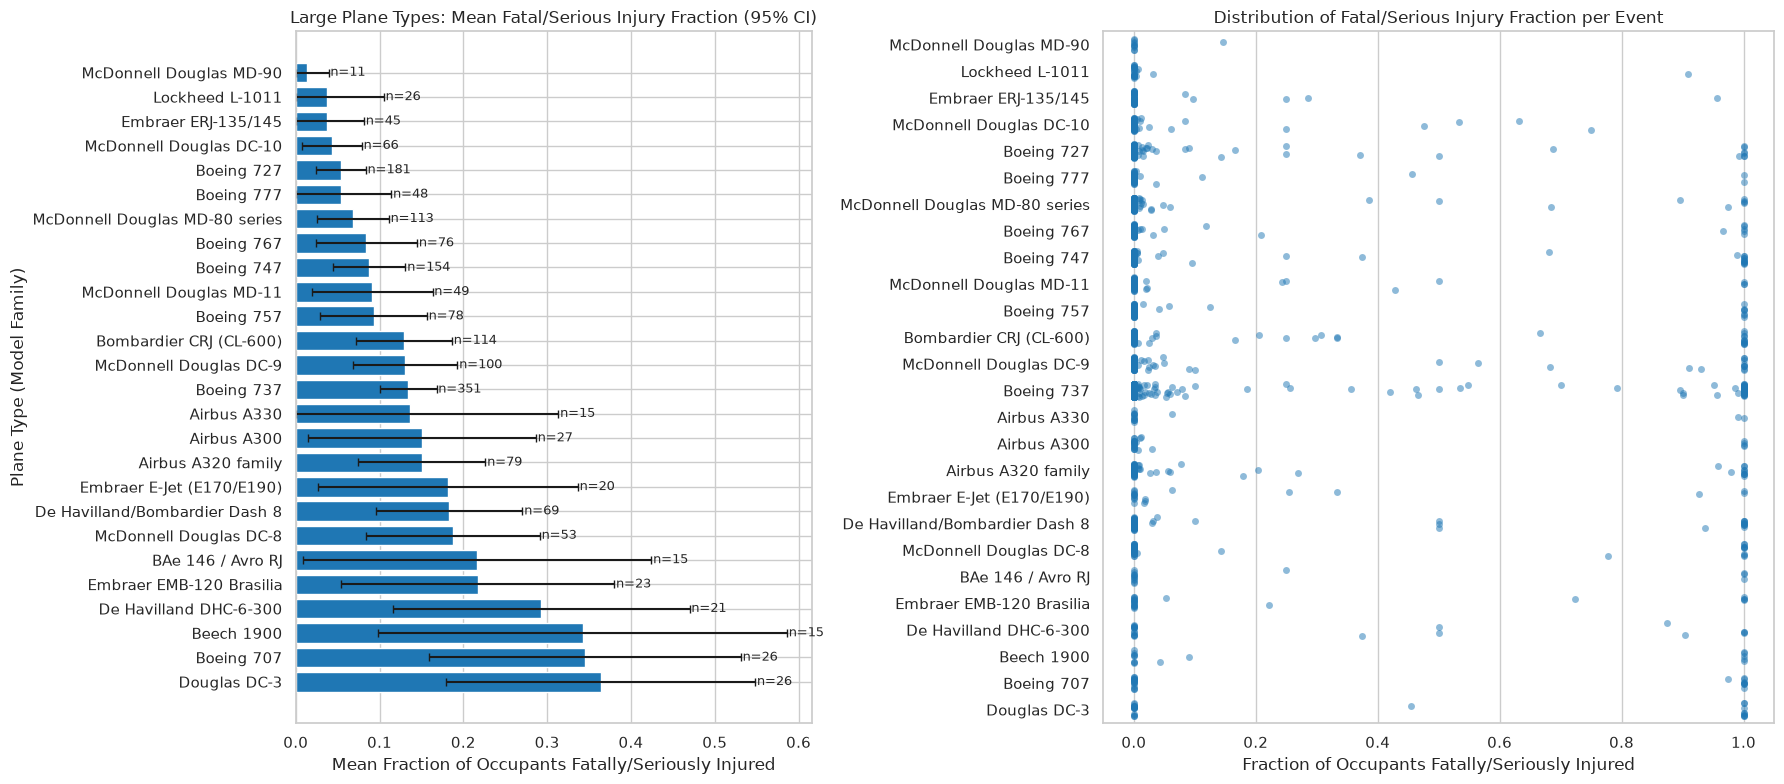

In [15]:
MIN_MODEL_EVENTS = 10   # at least ten individual events per plane type

large_models = safety_summary(large, 'Model.Family', MIN_MODEL_EVENTS).sort_values('mean_fatal_serious_frac')
print(f"Large plane types (model families) with >= {MIN_MODEL_EVENTS} events: {len(large_models)}")
display(large_models[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                      'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(4))

order = large_models.index
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1, 1.3]})
err = [large_models['mean_fatal_serious_frac'] - large_models['fs_ci_low'],
       large_models['fs_ci_high'] - large_models['mean_fatal_serious_frac']]
axes[0].barh(order[::-1], large_models['mean_fatal_serious_frac'][::-1],
             xerr=[e[::-1] for e in err], capsize=3, color='tab:blue')
for i, (name, row) in enumerate(large_models[::-1].iterrows()):
    axes[0].text(row['fs_ci_high'] + 0.002, i, f"n={int(row['n_events'])}", va='center', fontsize=9)
axes[0].set_title('Large Plane Types: Mean Fatal/Serious Injury Fraction (95% CI)')
axes[0].set_xlabel('Mean Fraction of Occupants Fatally/Seriously Injured')
axes[0].set_ylabel('Plane Type (Model Family)')

sns.stripplot(data=large[large['Model.Family'].isin(order)], y='Model.Family', x='Fatal.Serious.Fraction',
              order=order, jitter=0.25, alpha=0.5, color='tab:blue', ax=axes[1])
axes[1].set_title('Distribution of Fatal/Serious Injury Fraction per Event')
axes[1].set_xlabel('Fraction of Occupants Fatally/Seriously Injured')
axes[1].set_ylabel('')
fig.tight_layout()
save(fig, 'large_models')
plt.show()

small_top10_makes = small_makes.head(10).index
fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=small[small['Make'].isin(small_top10_makes)], x='Make', y='Fatal.Serious.Fraction',
               order=small_top10_makes, cut=0, inner='quartile', color='tab:orange', ax=ax)
ax.set_title('Distribution of Fatal/Serious Injury Fraction: 10 Lowest-Risk Small-Aircraft Makes')
ax.set_xlabel('Make')
ax.set_ylabel('Fraction of Occupants Fatally/Seriously Injured')
ax.tick_params(axis='x', rotation=30)
save(fig, 'small_makes_violin')
plt.show()

# How concentrated are the outcomes? Share of events with no fatal/serious injuries at all
(small[small['Make'].isin(small_top10_makes)]
     .groupby('Make')['Fatal.Serious.Fraction']
     .agg(share_no_serious_injury=lambda s: (s == 0).mean(),
          share_all_aboard_hurt=lambda s: (s == 1).mean(),
          median='median')
     .loc[small_top10_makes].round(3))

In [16]:
small_models = safety_summary(small, 'Make.Model', MIN_MODEL_EVENTS)
print(f"Small plane types with >= {MIN_MODEL_EVENTS} events: {len(small_models)}")

# Limit to makes with the 10 lowest mean fatal/serious fractions, then rank their plane types
small_models_top_makes = small_models[[any(idx.startswith(m + ' ') for m in small_top10_makes)
                                       for idx in small_models.index]]
best_small_models = small_models_top_makes.sort_values('mean_fatal_serious_frac').head(15)
display(best_small_models[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                           'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))

Small plane types with >= 10 events: 744


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Make.Model,,,,,,,
Maule MX-7-235,17,0.029,0.000,0.087,0.000,0.000,0.184
Maule M-7-235B,10,0.050,0.000,0.148,0.000,0.000,0.278
Maule M-4,18,0.056,0.000,0.164,0.056,0.010,0.258
Boeing Stearman E75,40,0.062,0.000,0.134,0.100,0.040,0.231
Swearingen SA226TC,32,0.068,0.000,0.153,0.062,0.017,0.201
Helio H295,11,0.091,0.000,0.269,0.000,0.000,0.259
Aviat A1B,10,0.100,0.000,0.296,0.000,0.000,0.278
Maule MX-7-180,10,0.100,0.000,0.296,0.000,0.000,0.278
Maule M-4-220C,37,0.108,0.014,0.202,0.081,0.028,0.213


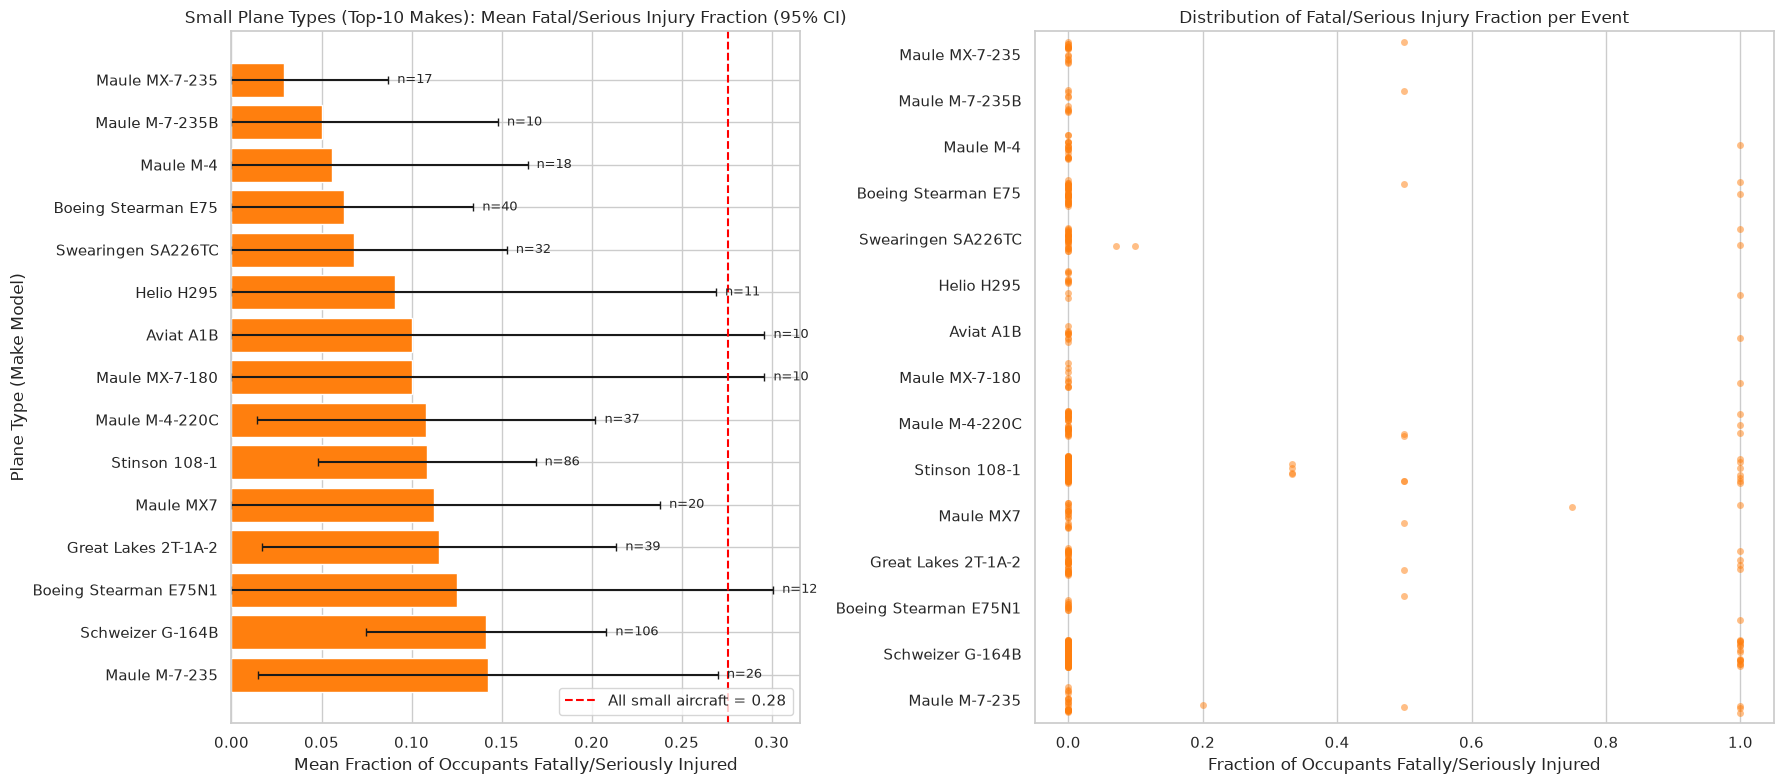

In [17]:
order = best_small_models.index
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1, 1.3]})
err = [best_small_models['mean_fatal_serious_frac'] - best_small_models['fs_ci_low'],
       best_small_models['fs_ci_high'] - best_small_models['mean_fatal_serious_frac']]
axes[0].barh(order[::-1], best_small_models['mean_fatal_serious_frac'][::-1],
             xerr=[e[::-1] for e in err], capsize=3, color='tab:orange')
axes[0].axvline(small['Fatal.Serious.Fraction'].mean(), color='red', linestyle='--',
                label=f"All small aircraft = {small['Fatal.Serious.Fraction'].mean():.2f}")
for i, (name, row) in enumerate(best_small_models[::-1].iterrows()):
    axes[0].text(row['fs_ci_high'] + 0.005, i, f"n={int(row['n_events'])}", va='center', fontsize=9)
axes[0].set_title('Small Plane Types (Top-10 Makes): Mean Fatal/Serious Injury Fraction (95% CI)')
axes[0].set_xlabel('Mean Fraction of Occupants Fatally/Seriously Injured')
axes[0].set_ylabel('Plane Type (Make Model)')
axes[0].legend(loc='lower right')

# Outcomes are bimodal (mostly 0, some 1), so a jittered strip plot shows the distribution better than a box plot
sns.stripplot(data=small[small['Make.Model'].isin(order)], y='Make.Model', x='Fatal.Serious.Fraction',
              order=order, jitter=0.3, alpha=0.5, color='tab:orange', ax=axes[1])
axes[1].set_title('Distribution of Fatal/Serious Injury Fraction per Event')
axes[1].set_xlabel('Fraction of Occupants Fatally/Seriously Injured')
axes[1].set_ylabel('')
fig.tight_layout()
save(fig, 'small_models')
plt.show()

The top-10-make list above is dominated by types with only 10–40 events, so their intervals are wide. An insurer will mostly write policies on **common** aircraft, so the next cell asks a more practical question: among small plane types with at least **100** events, which beat the small-fleet average on *both* injury fraction and destruction rate?

In [18]:
# The client will mostly insure common aircraft. Among small plane types with a large sample
# (>= 100 events), which have both low injury risk and a low destruction rate?
popular_small = safety_summary(small, 'Make.Model', 100)
popular_small = popular_small[(popular_small['mean_fatal_serious_frac'] < small['Fatal.Serious.Fraction'].mean()) &
                              (popular_small['destroyed_rate'] < small['Destroyed'].mean())]
popular_small.sort_values('mean_fatal_serious_frac')[['n_events', 'mean_fatal_serious_frac', 'fs_ci_high',
                                                      'destroyed_rate', 'destroyed_ci_high']].head(15).round(3)

,n_events,mean_fatal_serious_frac,fs_ci_high,destroyed_rate,destroyed_ci_high
Make.Model,,,,,
Piper PA-20,122,0.078,0.125,0.057,0.114
Cessna 185F,100,0.083,0.134,0.090,0.162
Cessna 180,593,0.111,0.135,0.078,0.102
Grumman G-164A,397,0.115,0.146,0.204,0.246
Cessna 170,151,0.121,0.170,0.086,0.142
Cessna 185,264,0.123,0.160,0.098,0.140
Piper PA-22,186,0.131,0.179,0.140,0.197
Cessna 170B,375,0.137,0.170,0.085,0.118
Schweizer G-164B,106,0.142,0.208,0.189,0.274


**How size is assigned.** The dataset has no seat-count column, and a single event is a noisy guide to aircraft size. A Boeing 747 freighter may be flying with 3 crew, and a light airplane involved in a collision can have the other aircraft's occupants recorded. Size is therefore assigned per **plane type**: a type is **Large** if the 90th percentile of people aboard across its events is above **20** *and* it is multi-engine. Every row of that type inherits the label.

**Large aircraft (model families, at least 10 events each)**

- **Widebodies:** the **Boeing 777** (injury fraction **0.055**, destroyed **8.3%**, n = 48), **Boeing 767** (0.084, 9.2%, n = 76) and **Boeing 747** (0.088, 10.4%, n = 154) all have low risk with reasonable samples. The 777 and 767 are still in production or service and are the strongest widebody recommendations.
- **Narrowbodies:** the **Boeing 757** (0.093, 7.7%, n = 78) and **MD-80 series** (0.068, 8.9%, n = 113) are among the best, and the **Boeing 727** (0.054, 7.2%, n = 181) has excellent figures but is now largely retired. The **Boeing 737** (0.134, 14.8%, n = 351) and **Airbus A320 family** (0.150, 13.9%, n = 79) are close to the large-aircraft average. Their intervals overlap, so neither is significantly safer than the other.
- **Regional jets:** the **Embraer ERJ-135/145** stands out, with **no hull losses in 45 events** (95% CI 0–7.9%) and an injury fraction of **0.037**. The **Bombardier CRJ** (0.129, 12.3%, n = 114) is around average.
- **Higher risk:** older and turboprop types (**Boeing 707, Douglas DC-3, Beech 1900, DHC-6 Twin Otter, EMB-120, BAe 146**) have the highest injury fractions (0.22–0.36) and destruction rates (22–38%).
- The **MD-90** and **Lockheed L-1011** look excellent, but with only 11 and 26 events their intervals are wide, so they are not recommended on this evidence alone.

**Small aircraft**

- Within the ten lowest-risk makes, **Maule** models dominate the safest types (MX-7-235, M-7-235B, M-4, M-4-220C, MX-7). Most have 10–40 events each, so the strongest evidence is at the Maule *make* level (570 events).
- Among **common** small aircraft (100 or more events) the best all-round performers are the **Cessna 172S** (injury 0.165, destroyed **6.9%**, n = 360) and **Cessna 172R** (0.158, 7.2%, n = 167). These current-production Skyhawks have about half the fleet's destruction rate (21%). The **Cessna 180/185** series (0.11–0.12, 8–10%) and the **Piper PA-18 Super Cub** (0.147, 8.8%, n = 547) are also strong.
- The **Cessna 152** trainer has a large sample (2,211 events) and a below-average injury fraction (0.155), but a more ordinary destruction rate (15.3%).

In [19]:
# Recommended specific plane types with their evidence
rec_large_types = ['Boeing 777', 'Boeing 767', 'Boeing 757', 'Boeing 747', 'Embraer ERJ-135/145',
                   'McDonnell Douglas MD-80 series']
rec_small_types = ['Cessna 172S', 'Cessna 172R', 'Cessna 180', 'Cessna 185', 'Piper PA-18']
small_types_all = safety_summary(small, 'Make.Model', MIN_MODEL_EVENTS)
pd.concat([large_models.loc[rec_large_types].assign(Group='Large'),
           small_types_all.loc[rec_small_types].assign(Group='Small')])[
    ['Group', 'n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
     'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3)

,Group,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Boeing 777,Large,48,0.055,0.000,0.114,0.083,0.033,0.196
Boeing 767,Large,76,0.084,0.024,0.145,0.092,0.045,0.178
Boeing 757,Large,78,0.093,0.029,0.157,0.077,0.036,0.158
Boeing 747,Large,154,0.088,0.044,0.131,0.104,0.065,0.162
Embraer ERJ-135/145,Large,45,0.037,0.000,0.082,0.000,0.000,0.079
McDonnell Douglas MD-80 series,Large,113,0.068,0.025,0.111,0.088,0.049,0.155
Cessna 172S,Small,360,0.165,0.127,0.202,0.069,0.047,0.101
Cessna 172R,Small,167,0.158,0.105,0.210,0.072,0.042,0.121
Cessna 180,Small,593,0.111,0.088,0.135,0.078,0.059,0.102
Cessna 185,Small,264,0.123,0.086,0.160,0.098,0.068,0.140


**Reading the strip plot:** large-aircraft accidents are overwhelmingly at or near 0. A typical airliner event is turbulence or a ground incident in which one or two of 150 people are seriously hurt. The mean is pulled up by a small number of cargo/ferry flights (few people aboard) and rare hull-loss crashes. McDonnell Douglas, Bombardier and Boeing combine low means with tight intervals. Lockheed's interval is very wide (only 31 events), so its low mean is not reliable.

### Factor 1: Weather condition

n_events  mean_fatal_serious_frac  fs_ci_low  \
Plane.Size Weather.Condition                                                 
Large      IMC                     251                    0.225      0.176   
           VMC                    1131                    0.069      0.055   
Small      IMC                    4574                    0.687      0.674   
           VMC                   51750                    0.225      0.222   

                              fs_ci_high  destroyed_rate  destroyed_ci_low  \
Plane.Size Weather.Condition                                                 
Large      IMC                     0.274           0.267             0.216   
           VMC                     0.083           0.075             0.061   
Small      IMC                     0.700           0.600             0.586   
           VMC                     0.229           0.170             0.167   

                              destroyed_ci_high  
Plane.Size Weather.Condition                     
Large      IMC                            0.325  
           VMC                            0.092  
Small      IMC                            0.614  
           VMC                            0.173

Small aircraft IMC vs VMC - injury fraction Welch t-test p = < 1e-300; destroyed chi-square p = < 1e-300


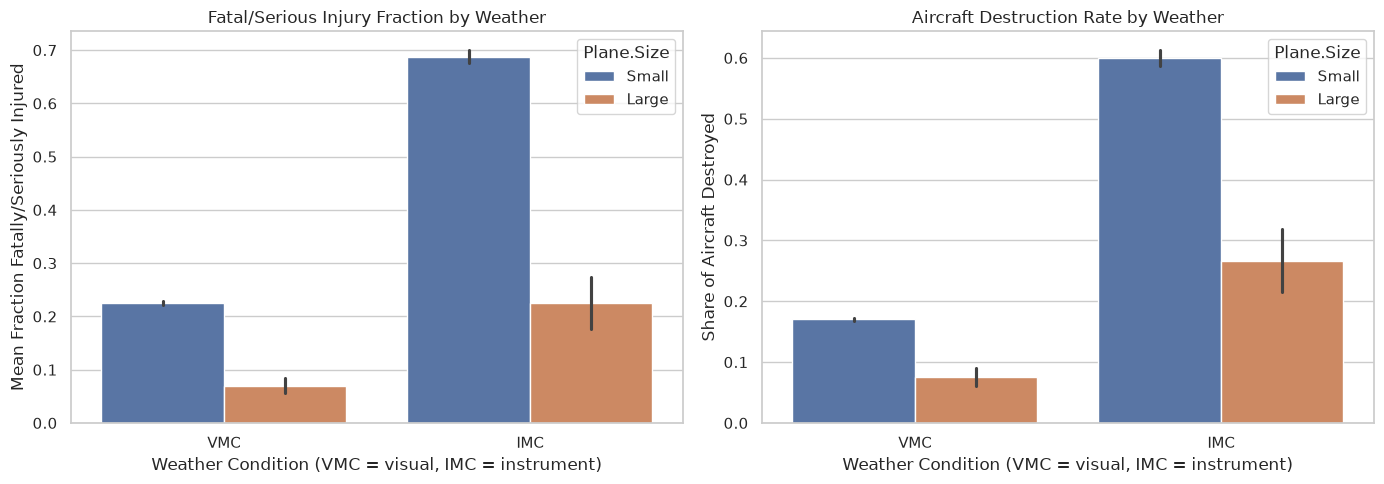

In [20]:
# Factor 1: Weather condition (VMC = visual, IMC = instrument conditions)
wx = df[df['Weather.Condition'].isin(['VMC', 'IMC'])]
wx_summary = safety_summary(wx, ['Plane.Size', 'Weather.Condition'])
display(wx_summary[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                    'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))

# Statistical tests (small aircraft, where most events are)
s_wx = wx[wx['Plane.Size'] == 'Small']
t = stats.ttest_ind(s_wx.loc[s_wx['Weather.Condition'] == 'IMC', 'Fatal.Serious.Fraction'],
                    s_wx.loc[s_wx['Weather.Condition'] == 'VMC', 'Fatal.Serious.Fraction'], equal_var=False)
chi = stats.chi2_contingency(pd.crosstab(s_wx['Weather.Condition'], s_wx['Destroyed']))
print(f"Small aircraft IMC vs VMC - injury fraction Welch t-test p = {fmt_p(t.pvalue)}; "
      f"destroyed chi-square p = {fmt_p(chi[1])}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=wx, x='Weather.Condition', y='Fatal.Serious.Fraction', hue='Plane.Size',
            order=['VMC', 'IMC'], errorbar=('ci', 95), ax=axes[0])
axes[0].set_title('Fatal/Serious Injury Fraction by Weather')
axes[0].set_xlabel('Weather Condition (VMC = visual, IMC = instrument)')
axes[0].set_ylabel('Mean Fraction Fatally/Seriously Injured')
sns.barplot(data=wx, x='Weather.Condition', y='Destroyed', hue='Plane.Size',
            order=['VMC', 'IMC'], errorbar=('ci', 95), ax=axes[1])
axes[1].set_title('Aircraft Destruction Rate by Weather')
axes[1].set_xlabel('Weather Condition (VMC = visual, IMC = instrument)')
axes[1].set_ylabel('Share of Aircraft Destroyed')
fig.tight_layout()
save(fig, 'factor_weather')
plt.show()

**Weather is the strongest single factor.** Accidents in instrument meteorological conditions (**IMC**: cloud, fog, low visibility) are far more severe than those in visual conditions (**VMC**):
- **Small aircraft:** in IMC, a mean **69%** of occupants are fatally or seriously injured and **60%** of aircraft are destroyed. In VMC the figures are **23%** and **17%**, so IMC is roughly three times worse on both metrics (p < 1e-300 for both tests, from about 4,600 IMC and 51,800 VMC events).
- **Large aircraft:** the same pattern holds at lower levels, with an injury fraction of **0.23** vs **0.07** and **27%** vs **7.5%** destroyed, and the confidence intervals don't overlap.

*Implication for the insurer:* operators and pilots who fly in IMC (an instrument rating, IFR-equipped aircraft, regular night or weather operations) carry materially higher severity risk. Weather exposure and pilot instrument currency should be underwriting factors.

### Factor 2: Engine type and number of engines

,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Engine.Type,,,,,,,
Turbo Fan,413,0.229,0.190,0.268,0.225,0.188,0.268
Reciprocating,52110,0.259,0.256,0.263,0.203,0.199,0.206
Turbo Prop,2569,0.321,0.303,0.338,0.273,0.256,0.290
Turbo Jet,193,0.393,0.326,0.460,0.378,0.313,0.448


,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Engines,,,,,,,
Single-engine,48954,0.252,0.248,0.255,0.188,0.185,0.192
Twin-engine,7258,0.355,0.344,0.365,0.320,0.310,0.331


Small aircraft twin vs single engine - injury Welch t-test p = 4.34e-70; destroyed chi-square p = 3.91e-148


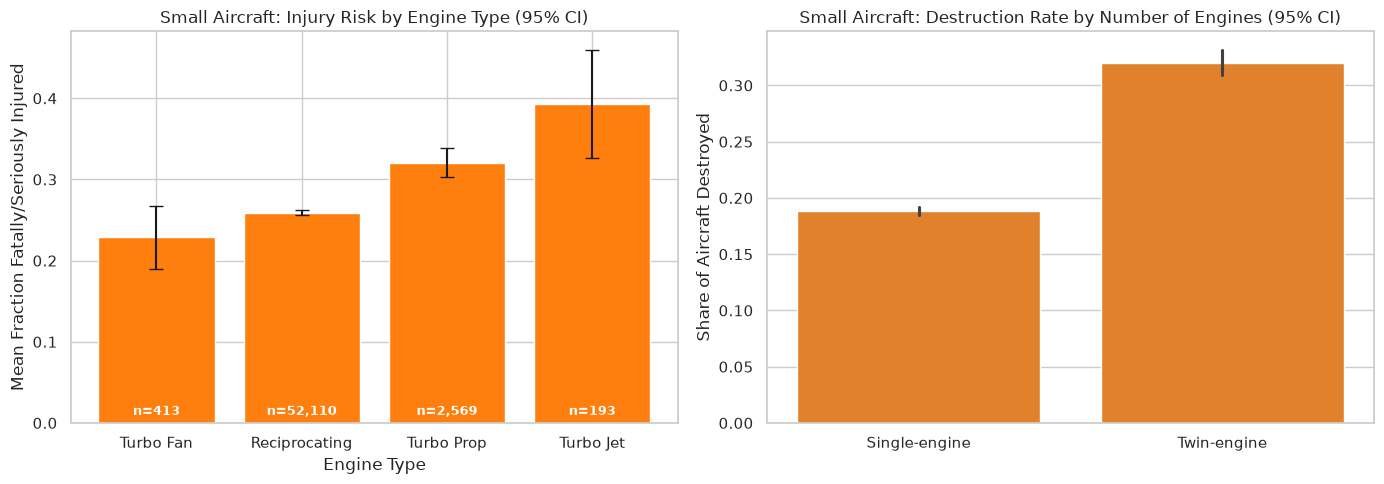

In [21]:
# Factor 2: Engine type and number of engines (small aircraft)
eng = small[small['Engine.Type'].isin(['Reciprocating', 'Turbo Prop', 'Turbo Fan', 'Turbo Jet'])]
eng_summary = safety_summary(eng, 'Engine.Type').sort_values('mean_fatal_serious_frac')
display(eng_summary[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                     'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))

ne = small[small['Number.of.Engines'].isin([1, 2])].copy()
ne['Engines'] = ne['Number.of.Engines'].map({1: 'Single-engine', 2: 'Twin-engine'})
ne_summary = safety_summary(ne, 'Engines')
display(ne_summary[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                    'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))
t = stats.ttest_ind(ne.loc[ne['Engines'] == 'Twin-engine', 'Fatal.Serious.Fraction'],
                    ne.loc[ne['Engines'] == 'Single-engine', 'Fatal.Serious.Fraction'], equal_var=False)
chi = stats.chi2_contingency(pd.crosstab(ne['Engines'], ne['Destroyed']))
print(f"Small aircraft twin vs single engine - injury Welch t-test p = {fmt_p(t.pvalue)}; destroyed chi-square p = {fmt_p(chi[1])}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df = eng_summary.reset_index()
axes[0].bar(plot_df['Engine.Type'], plot_df['mean_fatal_serious_frac'],
            yerr=[plot_df['mean_fatal_serious_frac'] - plot_df['fs_ci_low'],
                  plot_df['fs_ci_high'] - plot_df['mean_fatal_serious_frac']],
            capsize=5, color='tab:orange', label='Fatal/serious injury fraction')
axes[0].set_title('Small Aircraft: Injury Risk by Engine Type (95% CI)')
axes[0].set_xlabel('Engine Type')
axes[0].set_ylabel('Mean Fraction Fatally/Seriously Injured')
for i, n in enumerate(plot_df['n_events']):
    axes[0].text(i, 0.01, f"n={n:,}", ha='center', color='white', fontsize=9, fontweight='bold')
sns.barplot(data=ne, x='Engines', y='Destroyed', errorbar=('ci', 95), color='tab:orange', ax=axes[1])
axes[1].set_title('Small Aircraft: Destruction Rate by Number of Engines (95% CI)')
axes[1].set_xlabel('')
axes[1].set_ylabel('Share of Aircraft Destroyed')
fig.tight_layout()
save(fig, 'factor_engines')
plt.show()

**Engines matter, but mostly through how the aircraft is used.**
- Among small aircraft, **twin-engine** airplanes have *more* severe accidents than single-engine ones: an injury fraction of **0.355** vs **0.252** and **32%** vs **19%** destroyed (p ≈ 4e-70 and 4e-148). A second engine doesn't make accidents less severe. Twins fly faster and heavier, more often in IMC, at night and on business trips, so when they crash they crash harder.
- By **engine type**, piston (reciprocating) aircraft have the lowest destruction rate (**20%**). Small **turbo-jet** aircraft (older business jets) are the most severe, with an injury fraction of **0.39** and **38%** destroyed, while small turbofans are close to piston levels (0.23 injury). Turboprops are in between (0.32, 27%).

*Implication:* simple, slower, single-engine piston aircraft (the Maule, Aviat, Cub Crafters and Cessna 172/180/185 types recommended above) have the most survivable accident profile among small aircraft. Higher-performance twins and older jets should be priced for higher severity.

### Factor 3: Phase of flight

,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Broad.phase.of.flight,,,,,,,
Taxi,1522,0.016,0.011,0.021,0.022,0.016,0.031
Landing,12047,0.035,0.032,0.038,0.043,0.039,0.047
Standing,515,0.080,0.060,0.100,0.124,0.099,0.156
Takeoff,8984,0.226,0.218,0.234,0.219,0.211,0.228
Go-around,1172,0.299,0.274,0.324,0.288,0.262,0.314
Descent,1270,0.340,0.315,0.365,0.326,0.301,0.352
Cruise,7153,0.352,0.341,0.362,0.343,0.332,0.354
Approach,4599,0.353,0.339,0.366,0.300,0.287,0.313
Climb,1459,0.412,0.388,0.437,0.416,0.391,0.442


Phase of flight vs destroyed: chi-square p = < 1e-300; injury fraction Kruskal-Wallis p = < 1e-300


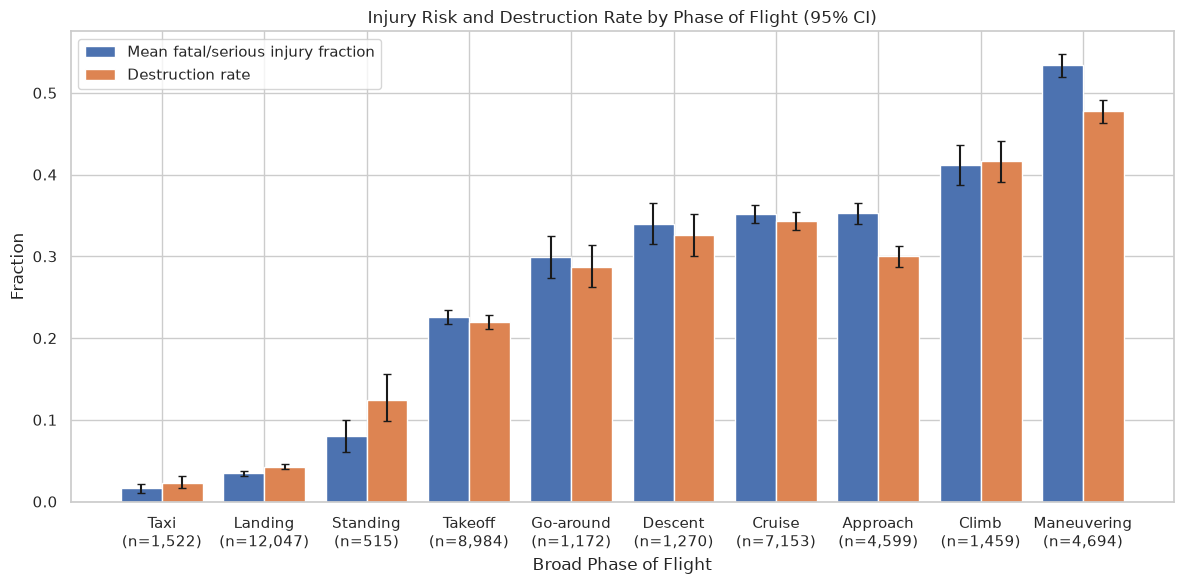

In [22]:
# Factor 3: Phase of flight (all airplanes; rows with unknown phase excluded)
phase = df[~df['Broad.phase.of.flight'].isin(['Unknown', 'Other'])]
phase_summary = safety_summary(phase, 'Broad.phase.of.flight', 100).sort_values('mean_fatal_serious_frac')
display(phase_summary[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                       'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3))
chi = stats.chi2_contingency(pd.crosstab(phase['Broad.phase.of.flight'], phase['Destroyed']))
anova = stats.kruskal(*[g['Fatal.Serious.Fraction'].values for _, g in phase.groupby('Broad.phase.of.flight')])
print(f"Phase of flight vs destroyed: chi-square p = {fmt_p(chi[1])}; injury fraction Kruskal-Wallis p = {fmt_p(anova.pvalue)}")

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(phase_summary))
w = 0.4
ax.bar(x - w/2, phase_summary['mean_fatal_serious_frac'], w,
       yerr=[phase_summary['mean_fatal_serious_frac'] - phase_summary['fs_ci_low'],
             phase_summary['fs_ci_high'] - phase_summary['mean_fatal_serious_frac']],
       capsize=3, label='Mean fatal/serious injury fraction')
ax.bar(x + w/2, phase_summary['destroyed_rate'], w,
       yerr=[phase_summary['destroyed_rate'] - phase_summary['destroyed_ci_low'],
             phase_summary['destroyed_ci_high'] - phase_summary['destroyed_rate']],
       capsize=3, label='Destruction rate')
ax.set_xticks(x)
ax.set_xticklabels([f"{p}\n(n={n:,})" for p, n in zip(phase_summary.index, phase_summary['n_events'])])
ax.set_title('Injury Risk and Destruction Rate by Phase of Flight (95% CI)')
ax.set_xlabel('Broad Phase of Flight')
ax.set_ylabel('Fraction')
ax.legend()
fig.tight_layout()
save(fig, 'factor_phase')
plt.show()

**Phase of flight strongly separates minor accidents from catastrophic ones** (chi-square and Kruskal-Wallis p < 1e-300):
- **Taxi, landing and standing** accidents are by far the most frequent (more than 14,000 events) but rarely cause serious harm. Injury fractions are **0.02–0.08** and only **2–12%** of aircraft are destroyed. These are mostly runway excursions, ground loops and hard landings.
- **Maneuvering, climb, cruise, approach and descent** are the dangerous phases. **Maneuvering** (low-altitude turns, aerobatics, aerial application) is the worst, with **53%** of occupants seriously or fatally injured and **48%** of aircraft destroyed, followed by **climb** (41%, 42%).

*Implication:* the frequency of claims will be driven by takeoff and landing mishaps, which are mostly hull damage. Severity (liability and hull loss) is driven by in-flight loss of control. Operations involving a lot of low-level maneuvering (agricultural, aerial observation, aerobatic) warrant higher premiums.

### Factor 4 (supporting): Purpose of flight

In [23]:
# Factor 4 (supporting): Purpose of flight, small aircraft, purposes with at least 300 events
purpose = small[small['Purpose.of.flight'] != 'Unknown']
purpose_summary = safety_summary(purpose, 'Purpose.of.flight', 300).sort_values('mean_fatal_serious_frac')
purpose_summary[['n_events', 'mean_fatal_serious_frac', 'fs_ci_low', 'fs_ci_high',
                 'destroyed_rate', 'destroyed_ci_low', 'destroyed_ci_high']].round(3)

,n_events,mean_fatal_serious_frac,fs_ci_low,fs_ci_high,destroyed_rate,destroyed_ci_low,destroyed_ci_high
Purpose.of.flight,,,,,,,
Instructional,8095,0.154,0.147,0.162,0.112,0.105,0.119
Aerial Application,3439,0.224,0.210,0.237,0.230,0.217,0.245
Ferry,550,0.275,0.238,0.311,0.298,0.261,0.338
Personal,35182,0.283,0.278,0.287,0.209,0.204,0.213
Positioning,1010,0.303,0.275,0.331,0.258,0.232,0.286
Other Work Use,521,0.308,0.270,0.346,0.238,0.203,0.276
Executive/corporate,370,0.312,0.267,0.358,0.308,0.263,0.357
Public Aircraft,400,0.333,0.288,0.378,0.262,0.222,0.308
Business,2963,0.345,0.328,0.361,0.309,0.292,0.326


**Purpose of flight** backs up the findings above. **Instructional** flights have the least severe accidents of any purpose with a large sample, with an injury fraction of **0.15** and **11%** destroyed, from more than 8,000 events. Training happens in visual conditions with an instructor aboard in docile aircraft. **Business**, **executive/corporate** and **aerial observation** flights are the most severe (0.31–0.42 injury fraction, about 30% destroyed), in line with the weather and engine findings: faster aircraft flown in more demanding conditions.

### Context: Trends Over Time

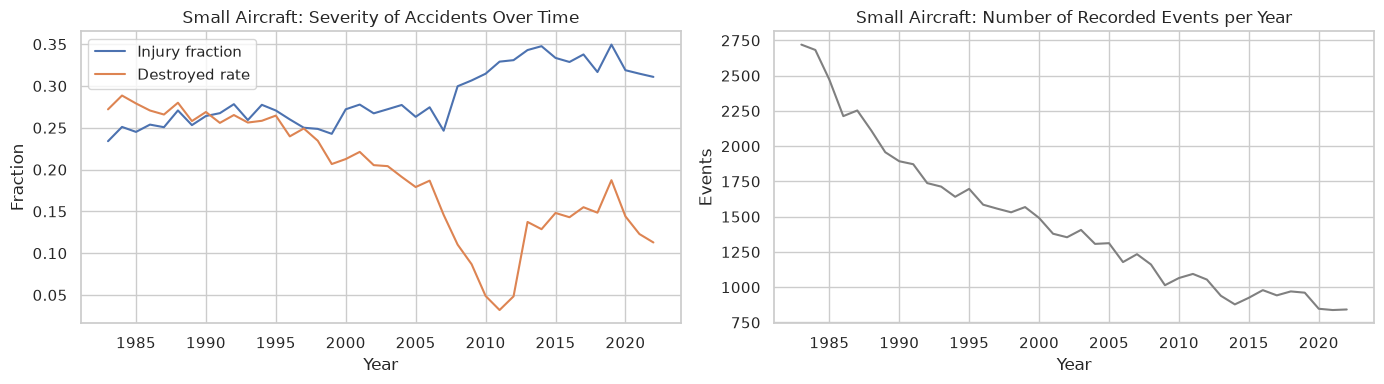

In [24]:
# Context: are accidents getting less severe over time? (useful for pricing older vs newer data)
trend = df.groupby(['Year', 'Plane.Size']).agg(events=('Event.Id', 'size'),
                                                injury=('Fatal.Serious.Fraction', 'mean'),
                                                destroyed=('Destroyed', 'mean')).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=trend[trend['Plane.Size'] == 'Small'], x='Year', y='injury', ax=axes[0], label='Injury fraction')
sns.lineplot(data=trend[trend['Plane.Size'] == 'Small'], x='Year', y='destroyed', ax=axes[0], label='Destroyed rate')
axes[0].set_title('Small Aircraft: Severity of Accidents Over Time')
axes[0].set_ylabel('Fraction')
sns.lineplot(data=trend[trend['Plane.Size'] == 'Small'], x='Year', y='events', ax=axes[1], color='gray')
axes[1].set_title('Small Aircraft: Number of Recorded Events per Year')
axes[1].set_ylabel('Events')
fig.tight_layout()
plt.show()

**Trends:** recorded accidents in this filtered dataset fell from about **2,800 a year** in 1983–85 to about **860 a year** in 2020–22. The share of accidents in which the aircraft was **destroyed also fell sharply**, from about 27% in the 1980s to about 12% since 2010. Over the same period the mean fatal/serious fraction *rose* (about 0.25 to 0.32). A likely explanation is that fewer minor, no-injury events have been recorded in recent years, so the accidents that remain skew more serious. The sharp dip in the destruction rate around 2008–2012 is also in the raw data: the share of all records marked "Destroyed" falls from 18% in 2006 to 4% in 2011 and returns to 13% in 2013. That pattern points to a temporary change in how damage was coded, not a real safety improvement. The insurer should give recent years more weight when pricing and should not read the rising injury fraction as aircraft becoming less safe.

## Recommendations to the Client

**1. Small aircraft: favor simple, rugged single-engine piston makes**
- **Maule** is the top recommendation (570 events). It has about half the fleet's serious-injury rate (0.155 vs 0.277) and less than half its destruction rate (9.3% vs 21.4%), and both differences are highly significant.
- **Aviat**, **Diamond** and **Cub Crafters** have the lowest destruction rates (0–7.5%), which matters most for hull coverage.
- For the high-volume market, the **Cessna 172S/172R Skyhawk** (about 7% destroyed vs a 21% fleet average, n = 527 combined), the **Cessna 180/185** and the **Piper PA-18 Super Cub** offer below-average risk on both metrics with large samples.

**2. Large aircraft: Boeing widebodies and Embraer regional jets**
- **Boeing** has the most evidence of any large make (945 events) with below-average injury and destruction rates. The **777**, **767**, **757** and **747** are the strongest specific types (injury fraction 0.055–0.093, destroyed 7.7–10.4%).
- For regional operators, the **Embraer ERJ-135/145** had no hull losses in 45 events and an injury fraction of 0.037. **McDonnell Douglas MD-80 series** aircraft (still common in cargo fleets) also perform well.
- Avoid or surcharge older and turboprop types (**Boeing 707, DC-3, Beech 1900, DHC-6, EMB-120, BAe 146**).

**3. Price in operating conditions, not just aircraft type**
- **Weather:** IMC accidents are about 3 times as severe (69% vs 23% injury fraction for small aircraft). Instrument-weather exposure should raise premiums.
- **Phase of flight and mission:** maneuvering and climb accidents are the most catastrophic, while taxi and landing accidents are frequent but minor. Agricultural, observation and business operations carry more severe risk than instructional and personal flying.
- **Engines:** twin-engine and turbojet small aircraft have *more* severe accidents than single-engine piston aircraft, so performance and mission matter more than engine redundancy.

### Limitations
- The dataset only contains accidents, so these metrics measure **how severe an accident is**, not **how likely an accident is**. Accident *rates* would need exposure data such as fleet sizes and flight hours, which this dataset doesn't include. Pairing these severity figures with FAA fleet and utilization data is the recommended next step.
- People aboard is estimated from the injury columns. Cargo and ferry flights carry few people, so one fatality can produce a high fraction.
- Some make/model labels may still be inconsistent after cleaning, and types with fewer than about 100 events should be treated as provisional, as their wide confidence intervals show.